In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
#Constantes 
a = 3.8e-4  #a = 2.8e-4 
b = 6e-3    #b = 5e-3
tau = .07   #tau = .1
k = -.005   #k = -.005


size = 150    # Tamaño de la matriz
dx = 4./ size # Define el paso espacial, distancia entre puntos adyacentes en la cuadrícula.

 
T = 9.0     # tiempo total de la simulación.
dt = .001   # paso temporal, incremento de tiempo entre cada iteración de la simulación.
n = int(T/dt)   # número total de iteraciones

In [3]:
U = np.random.rand(size, size) 
V = np.random.rand(size, size) 
Ztot=np.zeros([size, size]) 

In [4]:
def laplacian(Z):
    Ztop = Z[0:-2, 1:-1] 
    Zleft = Z[1:-1, 0:-2] 
    Zbottom = Z[2:, 1:-1] 
    Zright = Z[1:-1, 2:] 
    Zcenter = Z[1:-1, 1:-1] 
    return (Ztop + Zleft + Zbottom + Zright -
            4 * Zcenter) / dx**2   


In [5]:
def show_patterns(U, ax=None):
    ax.imshow(U, cmap=plt.cm.copper,
              interpolation='bilinear',
              extent=[-1, 1, -1, 1])
    ax.set_axis_off()


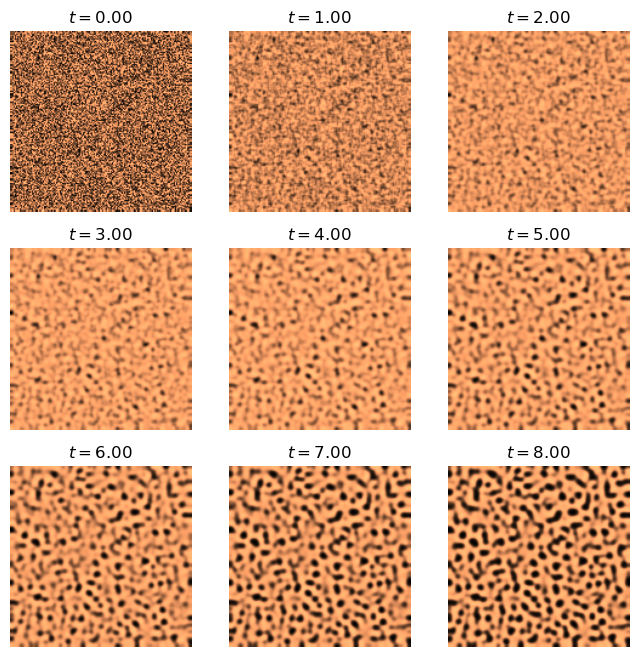

In [6]:
fig, axes = plt.subplots(3, 3, figsize=(8, 8))
step_plot = n // 9

for i in range(n):
    
    deltaU = laplacian(U)
    deltaV = laplacian(V)
   
    Uc = U[1:-1, 1:-1]
    Vc = V[1:-1, 1:-1]
    
    U[1:-1, 1:-1], V[1:-1, 1:-1] = \
        Uc + dt * (a * deltaU + Uc - Uc**3 - Vc + k),\
        Vc + dt * (b * deltaV + Uc - Vc) / tau
    
    
    
    for Z in (U, V):
        Z[0, :] = Z[1, :]
        Z[-1, :] = Z[-2, :]
        Z[:, 0] = Z[:, 1]
        Z[:, -1] = Z[:, -2]


        
    if i % step_plot == 0 and i < 9 * step_plot:
        ax = axes.flat[i // step_plot]
        show_patterns(U, ax=ax)
        ax.set_title(f'$t={i * dt:.2f}$')


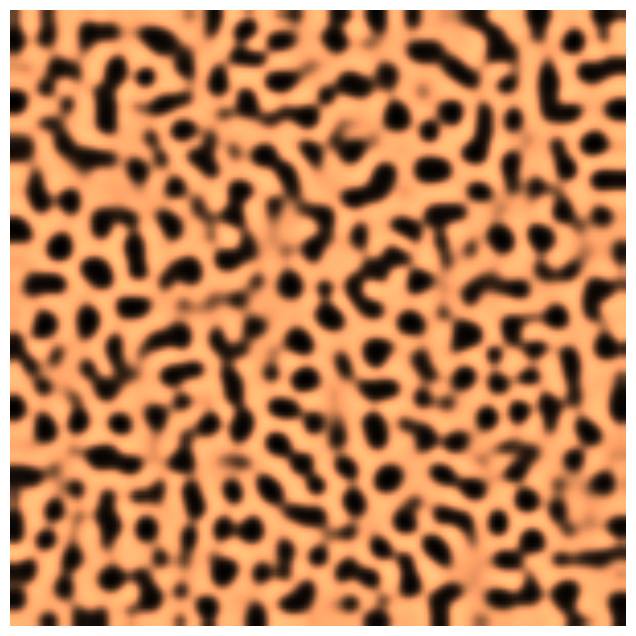

In [7]:
fig, ax = plt.subplots(1, 1, figsize=(8, 8))
show_patterns(U, ax=ax)

## Modificaciones para obtener un patrón de pez globoo

Se modifica el numero de iteraciones de 9000 a 32000 (y los colores de la grafica)

In [8]:
a = 3.8e-4  #a = 2.8e-4 
b = 6e-3    #b = 5e-3
tau = .07   #tau = .1
k = -.005   #k = -.005


size = 150    
dx = 4./ size 


T = 36.0     
dt = .001   
n = int(T/dt)   

In [9]:
U = np.random.rand(size, size) 
V = np.random.rand(size, size)

In [10]:
def show_patterns(U, ax=None):
    ax.imshow(U, cmap=plt.cm.viridis,
              interpolation='bilinear',
              extent=[-1, 1, -1, 1])
    ax.set_axis_off()

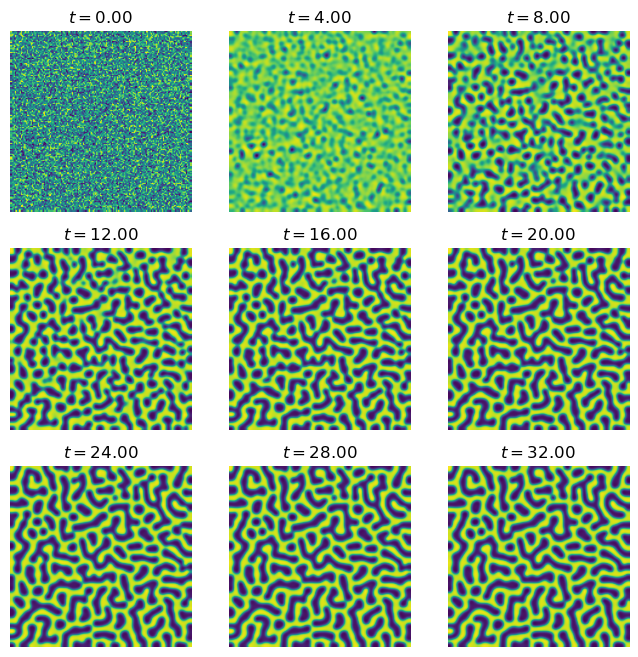

In [11]:
fig, axes = plt.subplots(3, 3, figsize=(8, 8))
step_plot = n // 9

for i in range(n):
    
    deltaU = laplacian(U) 
    deltaV = laplacian(V)
    Uc = U[1:-1, 1:-1]
    Vc = V[1:-1, 1:-1]

    U[1:-1, 1:-1], V[1:-1, 1:-1] = \
        Uc + dt * (a * deltaU + Uc - Uc**3 - Vc + k),\
        Vc + dt * (b * deltaV + Uc - Vc) / tau
    
    for Z in (U, V):
        Z[0, :] = Z[1, :]
        Z[-1, :] = Z[-2, :]
        Z[:, 0] = Z[:, 1]
        Z[:, -1] = Z[:, -2]

  
    if i % step_plot == 0 and i < 9 * step_plot:
        ax = axes.flat[i // step_plot]
        show_patterns(U, ax=ax)
        ax.set_title(f'$t={i * dt:.2f}$')


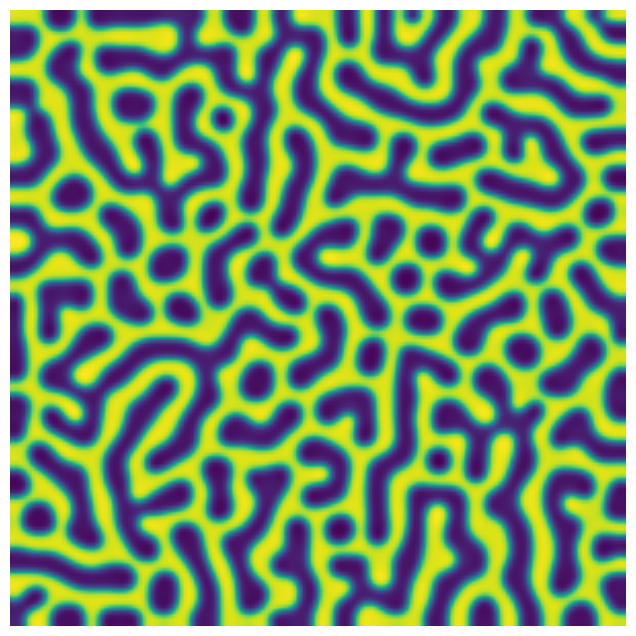

In [14]:
fig, ax = plt.subplots(1, 1, figsize=(8, 8))
show_patterns(U, ax=ax)